# Comparison of Bagging and Boosting Classifiers

Dataset Shape: (569, 30)

Target Classes:
['malignant' 'benign']

Training Samples: 455
Testing Samples: 114

========== BAGGING RESULTS ==========
Accuracy: 0.9386
Precision: 0.9452
Recall: 0.9583
F1 Score: 0.9517
Training Time: 4.2826 seconds

Bagging Confusion Matrix:
[[38  4]
 [ 3 69]]

Bagging Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



C:\Users\Student\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(



========== BOOSTING RESULTS ==========
Accuracy: 0.9561
Precision: 0.9467
Recall: 0.9861
F1 Score: 0.966
Training Time: 0.359 seconds

Boosting Confusion Matrix:
[[38  4]
 [ 1 71]]

Boosting Classification Report:
              precision    recall  f1-score   support

   malignant       0.97      0.90      0.94        42
      benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


========== MODEL COMPARISON ==========
      Model  Accuracy  Precision  Recall  F1 Score  Training Time (sec)
0   Bagging    0.9386     0.9452  0.9583    0.9517               4.2826
1  Boosting    0.9561     0.9467  0.9861    0.9660               0.3590


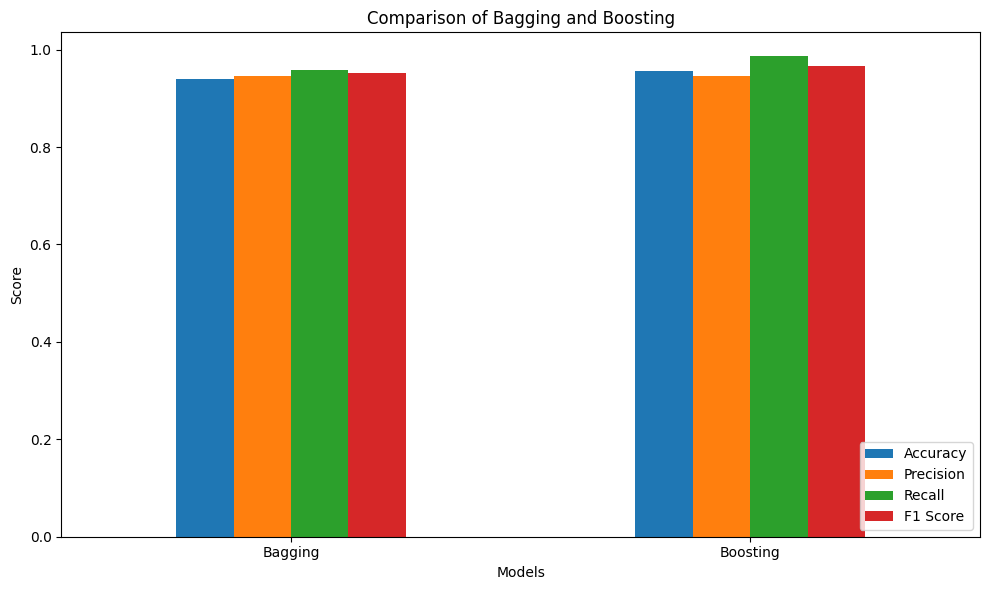

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
data = load_breast_cancer()
features = pd.DataFrame(data.data, columns=data.feature_names)
target = pd.Series(data.target, name="target")
print("Dataset Shape:", features.shape)
print("\nTarget Classes:")
print(data.target_names)
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)
print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# Create Bagging Classifier
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)
start_time = time.time()
bagging_model.fit(X_train, y_train)
bagging_training_time = time.time() - start_time
bagging_predictions = bagging_model.predict(X_test)
bagging_accuracy = accuracy_score(y_test, bagging_predictions)
bagging_precision = precision_score(y_test, bagging_predictions)
bagging_recall = recall_score(y_test, bagging_predictions)
bagging_f1 = f1_score(y_test, bagging_predictions)
print("\n========== BAGGING RESULTS ==========")
print("Accuracy:", round(bagging_accuracy, 4))
print("Precision:", round(bagging_precision, 4))
print("Recall:", round(bagging_recall, 4))
print("F1 Score:", round(bagging_f1, 4))
print("Training Time:", round(bagging_training_time, 4), "seconds")
print("\nBagging Confusion Matrix:")
print(confusion_matrix(y_test, bagging_predictions))
print("\nBagging Classification Report:")
print(classification_report(
    y_test,
    bagging_predictions,
    target_names=data.target_names
))
start_time = time.time()
boosting_model.fit(X_train, y_train)
boosting_training_time = time.time() - start_time
boosting_predictions = boosting_model.predict(X_test)
boosting_accuracy = accuracy_score(y_test, boosting_predictions)
boosting_precision = precision_score(y_test, boosting_predictions)
boosting_recall = recall_score(y_test, boosting_predictions)
boosting_f1 = f1_score(y_test, boosting_predictions)
print("\n========== BOOSTING RESULTS ==========")
print("Accuracy:", round(boosting_accuracy, 4))
print("Precision:", round(boosting_precision, 4))
print("Recall:", round(boosting_recall, 4))
print("F1 Score:", round(boosting_f1, 4))
print("Training Time:", round(boosting_training_time, 4), "seconds")
print("\nBoosting Confusion Matrix:")
print(confusion_matrix(y_test, boosting_predictions))
print("\nBoosting Classification Report:")
print(classification_report(
    y_test,
    boosting_predictions,
    target_names=data.target_names
))
results = pd.DataFrame({
    "Model": ["Bagging", "Boosting"],
    "Accuracy": [bagging_accuracy, boosting_accuracy],
    "Precision": [bagging_precision, boosting_precision],
    "Recall": [bagging_recall, boosting_recall],
    "F1 Score": [bagging_f1, boosting_f1],
    "Training Time (sec)": [
        bagging_training_time,
        boosting_training_time
    ]
})
print("\n========== MODEL COMPARISON ==========")
print(results.round(4))
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Bagging and Boosting")
plt.xlabel("Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()